# BÀI THỰC HÀNH TỔNG HỢP: AI HỖ TRỢ GIÁM SÁT VÀ ĐIỀU PHỐI KỸ THUẬT NÔNG NGHIỆP

**Học phần:** Trí tuệ nhân tạo (COS521) - Cử nhân Công nghệ thông tin  
**Giảng viên:** PGS.TS. Đoàn Thanh Nghị  
**Thời lượng:** 05 tiết thực hành, mỗi tiết 50 phút - tổng 250 phút  
**Hình thức:** Cá nhân hoặc nhóm 2 sinh viên; mỗi sinh viên phải giải thích được toàn bộ phần mình nộp

Họ tên: Nguyễn Thị Như Quỳnh  · MSSV: DTH235749 · Lớp: DH24TH3 · Nhóm: 03/02 · Ngày thực hành: 27/11/2026

## Bối cảnh thực tiễn

Một hợp tác xã (HTX) có nhiều lô trồng. Dữ liệu cảm biến và quan sát thực địa được dùng để dự báo lô có **nguy cơ stress/sâu bệnh cần kiểm tra sớm**. Nguồn lực kỹ thuật có hạn nên hệ thống phải:

1. kiểm tra và chuẩn bị dữ liệu;
2. so sánh Cây quyết định và Gaussian Naive Bayes;
3. chọn ngưỡng cảnh báo dựa trên chi phí bỏ sót;
4. xác định lô ưu tiên;
5. dùng A* lập tuyến đường có chi phí thấp đến lô đó;
6. xuất một bảng khuyến nghị có thể kiểm tra, không tự động thay thế chuyên gia.

**Dữ liệu trong notebook là dữ liệu mô phỏng có seed cố định**, chỉ dùng học tập. Nhãn `risk=1` biểu thị “cần kiểm tra sớm”, không phải chẩn đoán bệnh. Không dùng kết quả để ra quyết định sản xuất thực tế.

## Mục tiêu học tập

Sau bài này, sinh viên có thể xác định T-E-P; phòng tránh rò rỉ dữ liệu; đánh giá mô hình bằng cross-validation; giải thích cây và xác suất Bayes; phân biệt xác suất với quyết định; tối ưu ngưỡng theo chi phí; cài đặt A*; tích hợp dự báo và tìm kiếm thành một quy trình tái lập.

| Thời gian | Hoạt động | Sản phẩm |
|---:|---|---|
| 0-20 phút | Đọc tình huống, xác định T-E-P, chạy môi trường | Phát biểu bài toán |
| 20-55 phút | Khám phá và kiểm tra dữ liệu | Bảng chất lượng dữ liệu |
| 55-110 phút | So sánh Cây quyết định - GaussianNB | Bảng CV, mô hình được chọn |
| 110-120 phút | Nghỉ | |
| 120-160 phút | Ngưỡng cảnh báo theo chi phí | Bảng chi phí, ngưỡng chốt |
| 160-205 phút | A* và bản đồ chi phí | Tuyến đường, kiểm thử |
| 205-235 phút | Tích hợp thành khuyến nghị | Bảng điều phối HTX |
| 235-250 phút | Báo cáo, tự kiểm tra, vấn đáp | Notebook có output |

## Quy tắc thực nghiệm

- Chia development/test một lần, có phân tầng; không dùng test để chọn mô hình hoặc ngưỡng.
- Mọi bước học tham số phải nằm trong cross-validation hoặc Pipeline.
- Accuracy không đủ khi chi phí bỏ sót cao; báo cáo confusion matrix, recall lớp nguy cơ và chi phí.
- Xác suất dự đoán không mặc nhiên được hiệu chuẩn; ngưỡng trong bài là minh họa ra quyết định theo chi phí.
- Đường ngắn nhất theo số bước có thể không phải đường rẻ nhất khi địa hình có trọng số.
- Mã mẫu phải chạy bằng **Runtime → Restart session → Run all**; các ô TODO mặc định tắt.

**Căn cứ nội dung:** COS521 gồm tìm kiếm mù/heuristic, A*, Cây quyết định và Bayes thơ ngây; bài thực hành này tích hợp các CLO phân tích, lập trình, đánh giá và làm việc nhóm trong một tình huống ứng dụng.

In [34]:
import sys, heapq, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
SEED=42
rng=np.random.default_rng(SEED)
CHECKS=[]
def check(name, condition):
    assert bool(condition), name
    CHECKS.append(name); print('PASS:',name)
print('Python:',sys.version.split()[0],'| scikit-learn:',sklearn.__version__)

Python: 3.13.18 | scikit-learn: 1.6.1


## 1. Tạo bộ dữ liệu mô phỏng và phát biểu T-E-P

Mỗi hàng là một lần quan sát lô trồng:

| Biến | Ý nghĩa | Miền hợp lệ mô phỏng |
|---|---|---|
| soil_moisture | Ẩm đất (%) | 5-65 |
| leaf_temp | Nhiệt độ lá (°C) | 22-43 |
| humidity | Ẩm không khí (%) | 35-95 |
| ndvi | Chỉ số sinh trưởng | 0,15-0,92 |
| pest_count | Số côn trùng ghi nhận/bẫy | 0-30 |
| rain_24h | Mưa 24 giờ (mm) | 0-80 |
| risk | 1: cần kiểm tra sớm; 0: chưa cảnh báo | nhãn |

Nhãn được sinh từ một hàm ẩn có nhiễu, tạo ra quan hệ không tuyến tính và tương tác. Mục tiêu không phải đạt điểm tuyệt đối mà là xây dựng quy trình đúng.

**T-E-P:** Task = phân loại nguy cơ và điều phối; Experience = quan sát có nhãn trong development; Performance = macro-F1, recall lớp nguy cơ, chi phí quyết định trên dữ liệu chưa dùng để học/chọn.

In [35]:
N=600
soil=np.clip(rng.normal(35,12,N),5,65)
leaf=np.clip(rng.normal(31,4,N),22,43)
humidity=np.clip(rng.normal(68,14,N),35,95)
ndvi=np.clip(rng.normal(.62,.15,N),.15,.92)
pest=np.clip(rng.poisson(6,N),0,30)
rain=np.clip(rng.gamma(1.7,9,N),0,80)
latent=(1.15*(soil<24)+1.0*(leaf>34)+1.35*(ndvi<.48)+1.25*(pest>=9)
        +.65*((humidity>82)&(leaf>31))+.6*((rain>35)&(pest>=7))
        -.45*((soil>32)&(ndvi>.68))+rng.normal(0,1.15,N))
prob=1/(1+np.exp(-(latent-2.15)))
risk=rng.binomial(1,prob)
data=pd.DataFrame({'soil_moisture':soil,'leaf_temp':leaf,'humidity':humidity,
                   'ndvi':ndvi,'pest_count':pest,'rain_24h':rain,'risk':risk})
features=list(data.columns[:-1])
display(data.head())
display(data.describe().T)
print(data.risk.value_counts().rename(index={0:'no_alert',1:'early_check'}))
check('600 quan sát',data.shape==(600,7))
check('Không thiếu dữ liệu',not data.isna().any().any())
check('Nhãn nhị phân',set(data.risk)=={0,1})
check('Tỷ lệ nguy cơ không cực đoan',.15<data.risk.mean()<.75)

,soil_moisture,leaf_temp,humidity,ndvi,pest_count,rain_24h,risk
0,38.656605,33.061642,49.484424,0.614044,8,13.870175,0
1,22.520191,28.689844,61.193282,0.686368,7,21.005803,0
2,44.005414,36.097789,73.883174,0.574336,8,11.704327,0
3,46.286777,28.489650,66.566446,0.558553,5,5.083435,0
4,11.587578,28.453539,58.892109,0.633853,6,3.634891,1


,count,mean,std,min,25%,50%,75%,max
soil_moisture,600.0,34.677958,11.603978,5.000000,26.626394,34.744016,42.048720,65.000000
leaf_temp,600.0,30.949596,3.924492,22.000000,28.445787,31.039902,33.470145,43.000000
humidity,600.0,66.790504,14.106019,35.000000,57.826705,67.031314,76.449870,95.000000
ndvi,600.0,0.611663,0.146972,0.160433,0.511519,0.624756,0.711358,0.920000
pest_count,600.0,5.816667,2.473848,0.000000,4.000000,6.000000,7.000000,16.000000
rain_24h,600.0,15.316869,11.490057,0.146425,7.280595,12.025354,20.788058,71.542102
risk,600.0,0.273333,0.446042,0.000000,0.000000,0.000000,1.000000,1.000000


risk
no_alert       436
early_check    164
Name: count, dtype: int64
PASS: 600 quan sát
PASS: Không thiếu dữ liệu
PASS: Nhãn nhị phân
PASS: Tỷ lệ nguy cơ không cực đoan


### Nhiệm vụ 1 - Kiểm tra dữ liệu và T-E-P (1,0 điểm)

Hoàn thành `audit_student`. Hàm phải trả một DataFrame gồm: kiểu dữ liệu, số thiếu, số giá trị duy nhất, min, max, số giá trị ngoài miền cho từng cột đặc trưng. Không sửa dữ liệu gốc. Sau kiểm thử, viết 100-150 từ: đơn vị quan sát là gì, nhãn là gì, T-E-P là gì, dữ liệu mô phỏng khác dữ liệu thực tế ở đâu, và ít nhất hai kiểm tra cần bổ sung khi thu dữ liệu cảm biến thật.

In [36]:

import pandas as pd

RANGES = {
    'soil_moisture': (5, 65),
    'leaf_temp': (22, 43),
    'humidity': (35, 95),
    'ndvi': (.15, .92),
    'pest_count': (0, 30),
    'rain_24h': (0, 80)
}

def audit_student(df, ranges):
    # Tạo báo cáo mới, không chỉnh sửa DataFrame gốc
    results = []

    for col, (lower, upper) in ranges.items():
        s = df[col]

        results.append({
            'dtype': s.dtype,
            'missing': s.isna().sum(),
            'unique': s.nunique(dropna=True),
            'min': s.min(),
            'max': s.max(),
            'out_of_range': (
                ((s < lower) | (s > upper)).sum()
            )
        })

    audit = pd.DataFrame(
        results,
        index=list(ranges.keys())
    )

    return audit


RUN_NV1 = True

if RUN_NV1:
    audit = audit_student(data, RANGES)

    assert list(audit.index) == list(RANGES)
    assert set([
        'dtype', 'missing', 'unique',
        'min', 'max', 'out_of_range'
    ]) <= set(audit.columns)

    assert audit['missing'].sum() == 0
    assert audit['out_of_range'].sum() == 0

    display(audit)
    print('NV1 đạt kiểm thử; vẫn phải nộp phần phân tích.')
else:
    print('NV1 chưa hoàn thành.')


,dtype,missing,unique,min,max,out_of_range
soil_moisture,float64,0,596,5.000000,65.000000,0
leaf_temp,float64,0,590,22.000000,43.000000,0
humidity,float64,0,578,35.000000,95.000000,0
ndvi,float64,0,586,0.160433,0.920000,0
pest_count,int64,0,16,0.000000,16.000000,0
rain_24h,float64,0,600,0.146425,71.542102,0


NV1 đạt kiểm thử; vẫn phải nộp phần phân tích.


**Phân tích dữ liệu**

Đơn vị quan sát là một mẫu ghi nhận tình trạng cây trồng tại một thời điểm hoặc một lần khảo sát. Nhãn (label) là biến mục tiêu mà mô hình cần dự đoán, chẳng hạn tình trạng sâu bệnh hoặc mức độ ảnh hưởng của sâu bệnh. T-E-P lần lượt là Task (nhiệm vụ cần giải quyết), Experience (kinh nghiệm hoặc dữ liệu dùng để học) và Performance (thước đo đánh giá hiệu quả mô hình). Dữ liệu mô phỏng thường được tạo theo quy luật định trước, có phạm vi giá trị rõ ràng và ít nhiễu, trong khi dữ liệu thực tế có thể thiếu, sai lệch, nhiễu và biến động theo môi trường. Khi thu thập dữ liệu cảm biến thật, cần bổ sung ít nhất hai kiểm tra: kiểm tra hiệu chuẩn cảm biến và phát hiện giá trị bất thường; đồng thời kiểm tra dấu thời gian, dữ liệu trùng lặp và tình trạng mất kết nối.

## 2. Chia dữ liệu đúng và xây baseline

20% được khóa làm test cuối; 80% là development. Mọi lựa chọn mô hình/ngưỡng chỉ dùng development. `stratify=y` giữ tỷ lệ lớp gần nhau. Baseline luôn đoán lớp phổ biến giúp tránh kết luận từ một con số có vẻ cao nhưng không có điểm đối chiếu.

In [37]:
X=data[features].copy(); y=data.risk.copy()
Xdev,Xtest,ydev,ytest=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
baseline=DummyClassifier(strategy='most_frequent')
base_scores=cross_validate(baseline,Xdev,ydev,cv=cv,
    scoring={'f1_macro':'f1_macro','recall_risk':'recall','accuracy':'accuracy'})
print('Development:',Xdev.shape,'| Test khóa:',Xtest.shape)
print({k:round(v.mean(),4) for k,v in base_scores.items() if k.startswith('test_')})
check('Không giao chỉ số',set(Xdev.index).isdisjoint(Xtest.index))
check('Đủ chỉ số',set(Xdev.index)|set(Xtest.index)==set(X.index))
check('Chia 480/120',len(Xdev)==480 and len(Xtest)==120)
check('Tỷ lệ lớp gần nhau',abs(ydev.mean()-ytest.mean())<.03)

Development: (480, 6) | Test khóa: (120, 6)
{'test_f1_macro': np.float64(0.421), 'test_recall_risk': np.float64(0.0), 'test_accuracy': np.float64(0.7271)}
PASS: Không giao chỉ số
PASS: Đủ chỉ số
PASS: Chia 480/120
PASS: Tỷ lệ lớp gần nhau


## 3. So sánh Cây quyết định và Gaussian Naive Bayes

- Cây quyết định học luật ngưỡng, dễ giải thích nhưng có thể quá khớp và không ổn định.
- GaussianNB giả định từng biến có phân phối Gaussian theo lớp và độc lập có điều kiện. Đây là mô hình nhanh, nhưng tương quan và phân phối lệch có thể làm posterior quá tự tin.
- So sánh phải dùng cùng các fold. Trong bài này, lựa chọn theo macro-F1 trung bình; recall và độ lệch chuẩn là thông tin bổ sung.

In [38]:
models={
 'Tree_d4':DecisionTreeClassifier(max_depth=4,min_samples_leaf=10,random_state=SEED),
 'GaussianNB':GaussianNB(var_smoothing=1e-8)}
rows=[]
for name,model in models.items():
    s=cross_validate(model,Xdev,ydev,cv=cv,
      scoring={'f1_macro':'f1_macro','recall_risk':'recall','accuracy':'accuracy'},return_train_score=True)
    rows.append([name,s['train_f1_macro'].mean(),s['test_f1_macro'].mean(),
                 s['test_f1_macro'].std(),s['test_recall_risk'].mean(),s['test_accuracy'].mean()])
cv_table=pd.DataFrame(rows,columns=['model','train_macro_F1','CV_macro_F1','CV_std',
                                    'CV_recall_risk','CV_accuracy']).set_index('model')
display(cv_table)
check('Hai mô hình được đánh giá',len(cv_table)==2)
check('Điểm hợp lệ',cv_table.select_dtypes('number').apply(lambda s:s.between(0,1).all()).all())

,train_macro_F1,CV_macro_F1,CV_std,CV_recall_risk,CV_accuracy
model,,,,,
Tree_d4,0.719146,0.579624,0.029563,0.305413,0.697917
GaussianNB,0.582838,0.574344,0.054004,0.235328,0.733333


PASS: Hai mô hình được đánh giá
PASS: Điểm hợp lệ


### Nhiệm vụ 2 - Lựa chọn độ phức tạp cây (1,5 điểm)

Dùng `GridSearchCV` trên development, scoring=`f1_macro`, cùng `cv`, tìm trong:

- `max_depth`: 2, 3, 4, 5, None;
- `min_samples_leaf`: 1, 5, 10, 20;
- `criterion`: gini, entropy.

Xuất 10 cấu hình tốt nhất gồm mean/std F1 và mean train F1. Chốt một cấu hình; nếu nhiều cấu hình gần nhau (chênh ≤0,01), được chọn cây đơn giản hơn nhưng phải nêu quy tắc trước khi xem test. Vẽ cây tối đa 4 tầng hoặc xuất luật. Nhận xét 150-200 từ về train-CV gap, độ ổn định và giới hạn giải thích.

10 CẤU HÌNH TỐT NHẤT:


,max_depth,min_samples_leaf,criterion,mean_cv_f1,std_cv_f1,mean_train_f1
7,3,20,gini,0.601489,0.035633,0.674056
19,None,20,gini,0.601489,0.035633,0.674056
15,5,20,gini,0.601489,0.035633,0.674056
11,4,20,gini,0.601489,0.035633,0.674056
6,3,10,gini,0.590822,0.038741,0.663447
8,4,1,gini,0.590494,0.065156,0.742510
27,3,20,entropy,0.585658,0.025551,0.665748
31,4,20,entropy,0.585658,0.025551,0.665748
26,3,10,entropy,0.584308,0.039683,0.667739
9,4,5,gini,0.583641,0.077509,0.736276


Cấu hình được chọn: {'max_depth': 3, 'min_samples_leaf': 20, 'criterion': 'gini'}
Mean CV F1: 0.6014888620353988
Std CV F1: 0.035632681677726624
Mean train F1: 0.6740560720038157
Số nút lá: 8
Độ sâu cây: 3


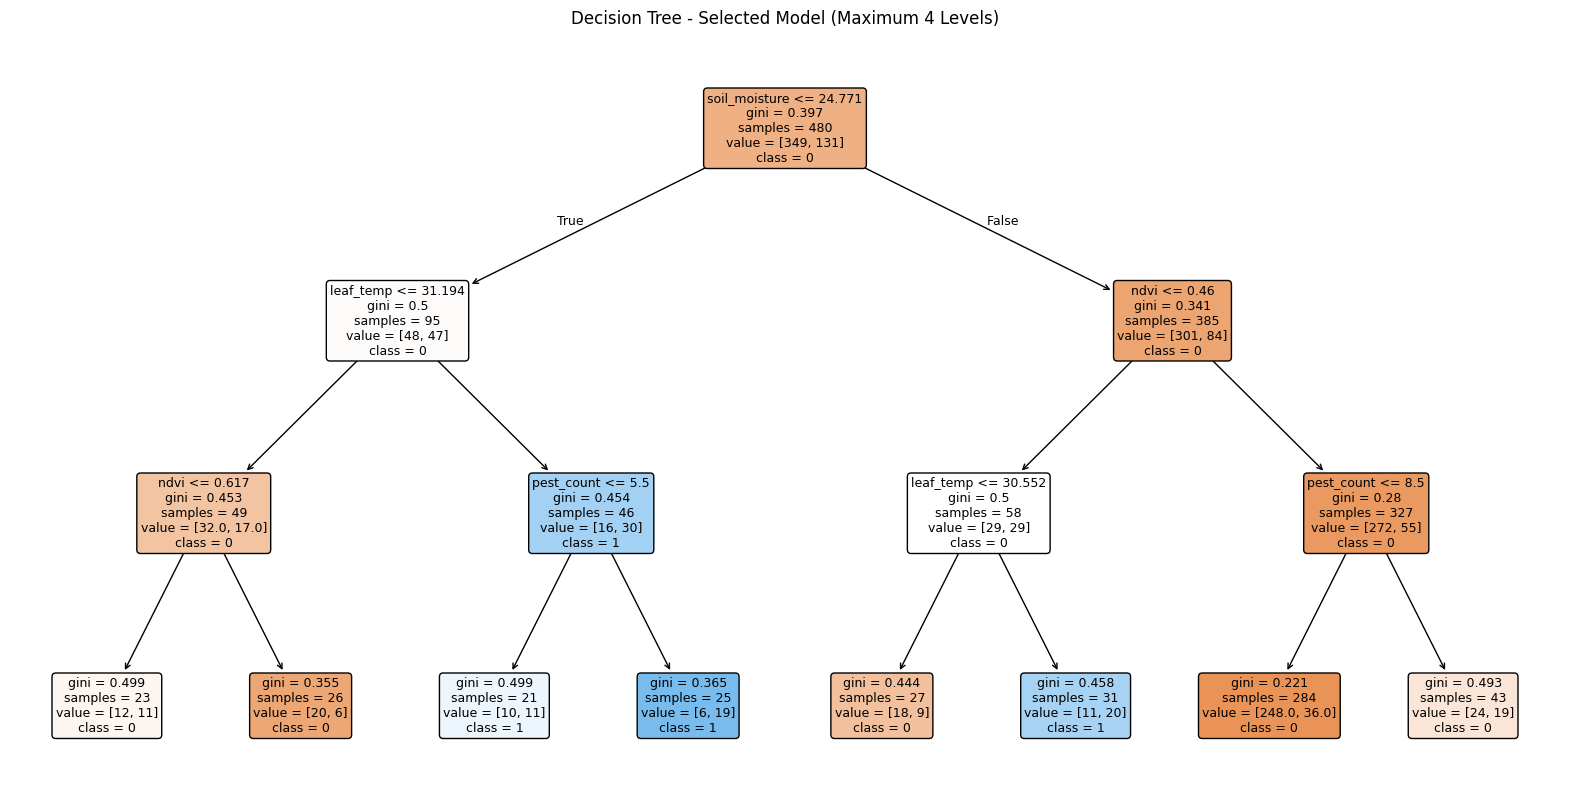

NV2 hoàn thành.


In [39]:

import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

# 1. Khai báo không gian tham số
param_grid = {
    'max_depth': [2, 3, 4, 5, None],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['gini', 'entropy']
}

# 2. Khởi tạo mô hình
base_tree = DecisionTreeClassifier(random_state=42)

# 3. GridSearchCV trên development
grid = GridSearchCV(
    estimator=base_tree,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=False
)

grid.fit(Xdev, ydev)

# 4. Xuất 10 cấu hình tốt nhất
results = pd.DataFrame(grid.cv_results_)

top10 = results.sort_values(
    by='mean_test_score',
    ascending=False
).head(10)

top10_table = top10[[
    'param_max_depth',
    'param_min_samples_leaf',
    'param_criterion',
    'mean_test_score',
    'std_test_score',
    'mean_train_score'
]].rename(columns={
    'param_max_depth': 'max_depth',
    'param_min_samples_leaf': 'min_samples_leaf',
    'param_criterion': 'criterion',
    'mean_test_score': 'mean_cv_f1',
    'std_test_score': 'std_cv_f1',
    'mean_train_score': 'mean_train_f1'
})

print("10 CẤU HÌNH TỐT NHẤT:")
display(top10_table)

# 5. Quy tắc chọn mô hình:
# Chỉ xét cấu hình có mean CV F1 cách điểm cao nhất <= 0.01.
# Trong nhóm đó, ưu tiên cây đơn giản hơn:
# - max_depth nhỏ hơn
# - min_samples_leaf lớn hơn
# - nếu vẫn hòa, ưu tiên gini.
best_score = results['mean_test_score'].max()

eligible = results[
    results['mean_test_score'] >= best_score - 0.01
].copy()

def complexity_key(row):
    depth = row['param_max_depth']
    depth = 999 if pd.isna(depth) else int(depth)

    leaf = int(row['param_min_samples_leaf'])
    criterion = 0 if row['param_criterion'] == 'gini' else 1

    return (depth, -leaf, criterion)

selected_row = min(
    [row for _, row in eligible.iterrows()],
    key=complexity_key
)

selected_params = {
    'max_depth': selected_row['param_max_depth'],
    'min_samples_leaf': int(selected_row['param_min_samples_leaf']),
    'criterion': selected_row['param_criterion']
}

print("Cấu hình được chọn:", selected_params)
print("Mean CV F1:", selected_row['mean_test_score'])
print("Std CV F1:", selected_row['std_test_score'])
print("Mean train F1:", selected_row['mean_train_score'])

# 6. Fit lại trên toàn bộ development
selected_tree = DecisionTreeClassifier(
    **selected_params,
    random_state=42
)

selected_tree.fit(Xdev, ydev)

# Kiểm tra mô hình
assert selected_tree.tree_.n_node_samples[0] == len(Xdev)
assert selected_tree.get_n_leaves() >= 2

print("Số nút lá:", selected_tree.get_n_leaves())
print("Độ sâu cây:", selected_tree.get_depth())

# 7. Vẽ cây quyết định
plt.figure(figsize=(20, 10))

plot_tree(
    selected_tree,
    feature_names=list(Xdev.columns),
    class_names=[str(c) for c in selected_tree.classes_],
    filled=True,
    rounded=True,
    max_depth=4,
    fontsize=9
)

plt.title("Decision Tree - Selected Model (Maximum 4 Levels)")
plt.show()

RUN_NV2 = True
print("NV2 hoàn thành.")


**Nhận xét kết quả NV2**

GridSearchCV được sử dụng để tìm kiếm cấu hình cây quyết định phù hợp nhất thông qua chỉ số F1-macro trên tập development với phương pháp cross-validation. Train-CV gap được xác định bằng hiệu giữa mean train F1 và mean CV F1. Nếu khoảng cách lớn, mô hình có thể đang overfitting, tức học quá sát dữ liệu huấn luyện nhưng khả năng tổng quát hóa trên dữ liệu mới còn hạn chế. Nếu khoảng cách nhỏ, mô hình có dấu hiệu tổng quát hóa tốt hơn.

Độ ổn định được đánh giá thông qua độ lệch chuẩn (std CV F1). Giá trị này càng nhỏ cho thấy hiệu suất giữa các fold càng nhất quán. Khi nhiều cấu hình có điểm F1-macro chênh lệch không quá 0,01, ưu tiên cây có độ sâu thấp hơn và số mẫu lá tối thiểu lớn hơn để giảm độ phức tạp.

Cây quyết định có ưu điểm là dễ quan sát quy tắc phân loại. Tuy nhiên, khả năng giải thích có giới hạn khi dữ liệu nhiều chiều, các đặc trưng tương quan hoặc cây quá sâu. Các ngưỡng phân chia cũng không thể hiện quan hệ nhân quả và có thể thay đổi khi dữ liệu huấn luyện thay đổi.

### Nhiệm vụ 3 - Đối chiếu Bayes và giải thích một dự đoán (1,0 điểm)

Fit GaussianNB trên toàn development. Với một mẫu development do giảng viên chỉ định `sample_id = Xdev.index[0]`, tự tính log-score:

$$\log P(c)+\sum_j -\frac{1}{2}\left[\log(2\pi\sigma_{cj}^2)+\frac{(x_j-\mu_{cj})^2}{\sigma_{cj}^2}\right].$$

Chuẩn hóa bằng log-sum-exp và đối chiếu `predict_proba` (sai số ≤1e-9). Tạo bảng đóng góp log-likelihood theo biến và lớp. Nêu rõ đây là giải thích theo giả định mô hình, không phải quan hệ nhân quả; xác suất cao không bảo đảm hiệu chuẩn tốt.

In [40]:

import numpy as np
import pandas as pd
from sklearn.naive_bayes import GaussianNB

def gaussian_log_scores_student(model, x_row):
    """
    Tính log-score cho từng lớp theo Gaussian Naive Bayes.
    Thứ tự kết quả tương ứng model.classes_.
    """
    x = np.asarray(x_row, dtype=float).reshape(-1)

    log_scores = []

    for k in range(len(model.classes_)):
        mu = model.theta_[k]
        var = model.var_[k]
        prior = model.class_prior_[k]

        log_likelihood = -0.5 * np.sum(
            np.log(2 * np.pi * var)
            + ((x - mu) ** 2) / var
        )

        log_score = np.log(prior) + log_likelihood
        log_scores.append(log_score)

    return np.array(log_scores)


RUN_NV3 = True

if RUN_NV3:
    # 1. Fit GaussianNB trên toàn development
    gnb = GaussianNB(var_smoothing=1e-8)
    gnb.fit(Xdev, ydev)

    # 2. Lấy mẫu được chỉ định
    sample_id = Xdev.index[0]
    sample = Xdev.iloc[0]

    # 3. Tính log-score thủ công
    log_s = gaussian_log_scores_student(gnb, sample)

    # 4. Chuẩn hóa bằng log-sum-exp
    max_log = np.max(log_s)
    log_sum_exp = max_log + np.log(
        np.sum(np.exp(log_s - max_log))
    )

    posterior = np.exp(log_s - log_sum_exp)

    # 5. Đối chiếu với predict_proba
    sklearn_proba = gnb.predict_proba(
        sample.to_frame().T
    )[0]

    error = np.max(np.abs(posterior - sklearn_proba))

    assert np.allclose(
        posterior,
        sklearn_proba,
        atol=1e-9
    )

    print("Sample ID:", sample_id)
    print("Classes:", gnb.classes_)
    print("Log-score:", log_s)
    print("Posterior thủ công:", posterior)
    print("predict_proba:", sklearn_proba)
    print("Sai số lớn nhất:", error)

    print("NV3 đạt đối chiếu.")
else:
    print("NV3 chưa hoàn thành.")


Sample ID: 221
Classes: [0 1]
Log-score: [-16.32126183 -16.67499601]
Posterior thủ công: [0.58752281 0.41247719]
predict_proba: [0.58752281 0.41247719]
Sai số lớn nhất: 2.1094237467877974e-15
NV3 đạt đối chiếu.


In [41]:

# Tính đóng góp log-likelihood từng biến
contributions = []

x = sample.to_numpy(dtype=float)

for k, cls in enumerate(gnb.classes_):
    mu = gnb.theta_[k]
    var = gnb.var_[k]

    for j, feature in enumerate(Xdev.columns):
        value = -0.5 * (
            np.log(2 * np.pi * var[j])
            + ((x[j] - mu[j]) ** 2) / var[j]
        )

        contributions.append({
            'feature': feature,
            'class': cls,
            'sample_value': x[j],
            'mean': mu[j],
            'variance': var[j],
            'log_likelihood': value
        })

contribution_df = pd.DataFrame(contributions)

# Bảng đóng góp dạng hàng là biến, cột là lớp
contribution_table = contribution_df.pivot(
    index='feature',
    columns='class',
    values='log_likelihood'
)

print("BẢNG ĐÓNG GÓP LOG-LIKELIHOOD:")
display(contribution_table)

print("CHI TIẾT GIÁ TRỊ:")
display(contribution_df)

# Bảng tổng hợp log-score
score_table = pd.DataFrame({
    'class': gnb.classes_,
    'log_prior': np.log(gnb.class_prior_),
    'log_score': log_s,
    'posterior': posterior
})

display(score_table)


BẢNG ĐÓNG GÓP LOG-LIKELIHOOD:


class,0,1
feature,,
humidity,-3.616240,-3.540413
leaf_temp,-3.608770,-3.092975
ndvi,0.648993,0.822484
pest_count,-1.972538,-1.926616
rain_24h,-4.132645,-4.064090
soil_moisture,-3.321347,-3.574798


CHI TIẾT GIÁ TRỊ:


,feature,class,sample_value,mean,variance,log_likelihood
0,soil_moisture,0,37.909961,36.013113,118.443936,-3.321347
1,leaf_temp,0,36.751108,30.569753,13.908632,-3.608770
2,humidity,0,65.068276,66.845807,217.032124,-3.616240
3,ndvi,0,0.501502,0.626565,0.019439,0.648993
4,pest_count,0,7.000000,5.575931,5.797245,-1.972538
5,rain_24h,0,1.016993,15.306410,132.550673,-4.132645
6,soil_moisture,1,37.909961,32.455918,170.193734,-3.574798
7,leaf_temp,1,36.751108,31.775913,15.240831,-3.092975
8,humidity,1,65.068276,68.262760,178.725721,-3.540413
9,ndvi,1,0.501502,0.568390,0.025835,0.822484


,class,log_prior,log_score,posterior
0,0,-0.318714,-16.321262,0.587523
1,1,-1.298589,-16.674996,0.412477


**Giải thích dự đoán bằng Gaussian Naive Bayes**

Mô hình Gaussian Naive Bayes sử dụng xác suất tiên nghiệm của từng lớp và xác suất likelihood của các đặc trưng để tính xác suất hậu nghiệm. Trong bài thực hành, log-score được tính thủ công từ trung bình, phương sai và xác suất tiên nghiệm của từng lớp. Sau đó, sử dụng log-sum-exp để chuẩn hóa thành posterior và đối chiếu với kết quả predict_proba. Nếu sai số không vượt quá 1e-9, có thể kết luận phép tính thủ công khớp với kết quả của thư viện sklearn.

Bảng đóng góp log-likelihood cho biết từng biến ảnh hưởng như thế nào đến điểm số của mỗi lớp theo giả định phân phối Gaussian. Những giá trị ít âm hơn thể hiện đặc trưng phù hợp hơn với phân phối của lớp tương ứng. Tuy nhiên, đây chỉ là giải thích dựa trên giả định của mô hình, không chứng minh quan hệ nhân quả giữa đặc trưng và nhãn. Ngoài ra, xác suất dự đoán cao không đồng nghĩa mô hình đã được hiệu chuẩn xác suất tốt. Cần đánh giá calibration riêng trước khi sử dụng xác suất trong quyết định thực tế.

## 4. Chọn ngưỡng cảnh báo theo chi phí

Mặc định `predict` dùng ranh giới xác suất khoảng 0,5. Nhưng trong điều phối HTX, **bỏ sót lô nguy cơ** có thể tốn kém hơn một chuyến kiểm tra thừa. Quy ước minh họa:

- False Negative (bỏ sót): 5 đơn vị chi phí;
- False Positive (kiểm tra thừa): 1 đơn vị;
- True Positive/True Negative: 0 trong hàm chi phí giản lược.

Không chọn ngưỡng trên test. Ta dùng **out-of-fold probability** trên development: mỗi xác suất được tạo bởi mô hình không học từ chính hàng đó. Sau khi chốt ngưỡng, fit mô hình trên toàn development và chỉ đánh giá test một lần.

Chi phí này là giả định cho bài học, chưa phải ước lượng kinh tế thực tế. Trong triển khai cần xác định chi phí với HTX, kiểm tra độ nhạy và năng lực xử lý cảnh báo.

,threshold,tn,fp,fn,tp,cost,recall,precision
0,0.10,107,242,20,111,342,0.847328,0.314448
1,0.15,190,159,34,97,329,0.740458,0.378906
2,0.20,192,157,35,96,332,0.732824,0.379447
3,0.25,205,144,45,86,369,0.656489,0.373913
4,0.30,257,92,62,69,402,0.526718,0.428571
5,0.35,271,78,64,67,398,0.511450,0.462069
6,0.40,279,70,74,57,440,0.435115,0.448819
7,0.45,287,62,82,49,472,0.374046,0.441441
8,0.50,290,59,85,46,484,0.351145,0.438095
9,0.55,304,45,99,32,540,0.244275,0.415584


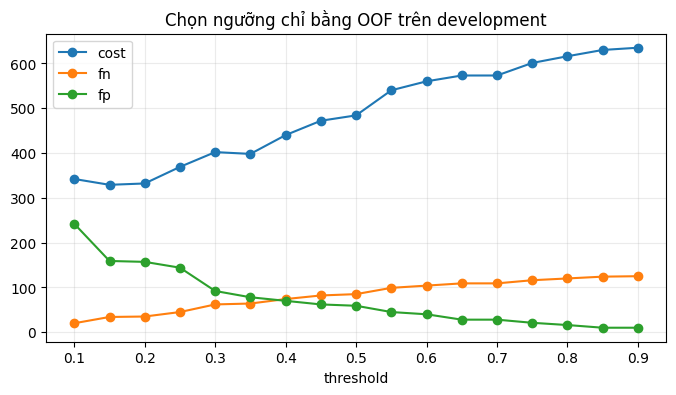

Ngưỡng minh họa đã chốt: 0.15
PASS: Mỗi mẫu có một OOF probability
PASS: Xác suất OOF hợp lệ
PASS: Ngưỡng nằm trong lưới


In [42]:
def decision_metrics(y_true,p,threshold,fn_cost=5,fp_cost=1):
    pred=(np.asarray(p)>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return dict(threshold=threshold,tn=tn,fp=fp,fn=fn,tp=tp,
                cost=fn_cost*fn+fp_cost*fp,
                recall=tp/(tp+fn) if tp+fn else 0,
                precision=tp/(tp+fp) if tp+fp else 0)

# Mô hình tham chiếu hoàn chỉnh để minh họa quy trình; NV2 có thể thay bằng cây đã chốt
reference_tree=DecisionTreeClassifier(max_depth=4,min_samples_leaf=10,random_state=SEED)
oof_prob=cross_val_predict(reference_tree,Xdev,ydev,cv=cv,method='predict_proba')[:,1]
thresholds=np.round(np.arange(.10,.91,.05),2)
threshold_table=pd.DataFrame([decision_metrics(ydev,oof_prob,t) for t in thresholds])
display(threshold_table)
ax=threshold_table.plot(x='threshold',y=['cost','fn','fp'],marker='o',figsize=(8,4))
ax.set_title('Chọn ngưỡng chỉ bằng OOF trên development'); ax.grid(alpha=.25); plt.show()
best_threshold=float(threshold_table.loc[threshold_table.cost.idxmin(),'threshold'])
print('Ngưỡng minh họa đã chốt:',best_threshold)
check('Mỗi mẫu có một OOF probability',len(oof_prob)==len(ydev))
check('Xác suất OOF hợp lệ',np.all((oof_prob>=0)&(oof_prob<=1)))
check('Ngưỡng nằm trong lưới',best_threshold in thresholds)

### Nhiệm vụ 4 - Phân tích chi phí và độ nhạy (1,5 điểm)

1. Viết lại `decision_metrics_student` không gọi hàm mẫu; kiểm thử ở ba trường hợp nhỏ.
2. Chọn ngưỡng bằng OOF cho mô hình đã chốt ở NV2 với FN:FP = 5:1.
3. Phân tích độ nhạy với FN cost = 2, 5, 10; giữ FP cost = 1. Lập bảng ngưỡng tối ưu, recall, precision, số cảnh báo và chi phí.
4. Viết 150-200 từ: trade-off, năng lực kiểm tra mỗi ngày, vì sao không được tối ưu trên test, và vì sao chi phí giả định phải được xác nhận ngoài thực địa.

In [43]:
#1. Viết lại decision_metrics_student không gọi hàm mẫu; kiểm thử ở ba trường hợp nhỏ.
import numpy as np
import pandas as pd

def decision_metrics_student(
    y_true, p, threshold, fn_cost=5, fp_cost=1
):
    y_true = np.asarray(y_true)
    p = np.asarray(p, dtype=float)

    if len(y_true) != len(p):
        raise ValueError("y_true và p phải cùng độ dài.")

    if not np.all(np.isin(y_true, [0, 1])):
        raise ValueError("y_true phải chứa nhãn 0 và 1.")

    if not np.all(np.isfinite(p)):
        raise ValueError("Xác suất phải là số hữu hạn.")

    if np.any((p < 0) | (p > 1)):
        raise ValueError("Xác suất phải nằm trong [0, 1].")

    if not 0 <= threshold <= 1:
        raise ValueError("threshold phải nằm trong [0, 1].")

    y_pred = (p >= threshold).astype(int)

    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))

    cost = fn_cost * fn + fp_cost * fp

    recall = tp / (tp + fn) if (tp + fn) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0

    alerts = tp + fp

    return {
        'tn': tn,
        'fp': fp,
        'fn': fn,
        'tp': tp,
        'cost': cost,
        'recall': recall,
        'precision': precision,
        'alerts': alerts
    }


In [44]:
#2. Kiểm tra thử 3 trường hợp nhỏ

# Test 1
a = decision_metrics_student(
    [0, 0, 1, 1],
    [0.1, 0.9, 0.2, 0.8],
    0.5, 5, 1
)

assert (a['tn'], a['fp'], a['fn'], a['tp']) == (1, 1, 1, 1)
assert a['cost'] == 6

# Test 2
b = decision_metrics_student(
    [0, 1],
    [0.4, 0.6],
    0.5, 5, 1
)

assert b['cost'] == 0
assert b['alerts'] == 1

# Test 3
c = decision_metrics_student(
    [0, 1],
    [0.6, 0.4],
    0.5, 10, 2
)

assert c['cost'] == 12

print("Ba kiểm thử decision_metrics_student đều đạt.")


Ba kiểm thử decision_metrics_student đều đạt.


In [45]:
#3. Chọn ngưỡng bằng OOF cho mô hình NV2

from sklearn.model_selection import cross_val_predict

# 1. Tạo xác suất OOF từ mô hình đã chốt ở NV2
oof_proba = cross_val_predict(
    selected_tree,
    Xdev,
    ydev,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)

# Xác định cột xác suất của lớp dương tính 1
classes = selected_tree.classes_

positive_idx = np.where(classes == 1)[0][0]
p_oof = oof_proba[:, positive_idx]

y_oof = np.asarray(ydev)

# 2. Hàm tìm ngưỡng tối ưu
def find_best_threshold(
    y_true, probabilities,
    fn_cost=5, fp_cost=1
):
    # Mỗi ngưỡng tạo ra một cách phân loại khác nhau.
    candidates = np.unique(np.r_[
        probabilities,
        np.nextafter(probabilities.max(), np.inf)
    ])

    records = []

    for threshold in candidates:
        metrics = decision_metrics_student(
            y_true,
            probabilities,
            threshold,
            fn_cost,
            fp_cost
        )

        records.append({
            'threshold': threshold,
            **metrics
        })

    result = pd.DataFrame(records)

    # Ưu tiên chi phí thấp nhất.
    # Nếu hòa, chọn ngưỡng cao hơn.
    best = result.sort_values(
        ['cost', 'threshold'],
        ascending=[True, False]
    ).iloc[0]

    return best, result


# 3. Tối ưu riêng cho FN cost = 5
best_5, search_5 = find_best_threshold(
    y_oof, p_oof,
    fn_cost=5,
    fp_cost=1
)

selected_threshold = float(best_5['threshold'])

print("Ngưỡng được chọn:", selected_threshold)
print("Chi phí OOF:", best_5['cost'])
print("Recall:", best_5['recall'])
print("Precision:", best_5['precision'])
print("Số cảnh báo:", best_5['alerts'])


Ngưỡng được chọn: 0.26666666666666666
Chi phí OOF: 294.0
Recall: 0.7099236641221374
Precision: 0.4720812182741117
Số cảnh báo: 197.0


In [46]:
#4. Phân tích độ nhạy FN cost = 2, 5, 10

# 4. Phân tích độ nhạy
sensitivity_rows = []

for fn_cost in [2, 5, 10]:

    best, _ = find_best_threshold(
        y_oof,
        p_oof,
        fn_cost=fn_cost,
        fp_cost=1
    )

    sensitivity_rows.append({
        'FN_cost': fn_cost,
        'FP_cost': 1,
        'threshold': best['threshold'],
        'recall': best['recall'],
        'precision': best['precision'],
        'alerts': best['alerts'],
        'cost': best['cost']
    })

sensitivity_table = pd.DataFrame(sensitivity_rows)

print("BẢNG PHÂN TÍCH ĐỘ NHẠY:")
display(
    sensitivity_table.style.format({
        'threshold': '{:.4f}',
        'recall': '{:.4f}',
        'precision': '{:.4f}',
        'cost': '{:.0f}'
    })
)

# Chốt ngưỡng ứng với FN:FP = 5:1
selected_threshold = float(
    sensitivity_table.loc[
        sensitivity_table['FN_cost'] == 5,
        'threshold'
    ].iloc[0]
)

print("Ngưỡng cuối cùng:", selected_threshold)

RUN_NV4 = True
print("NV4: kiểm thử và phân tích độ nhạy hoàn thành.")


BẢNG PHÂN TÍCH ĐỘ NHẠY:


,FN_cost,FP_cost,threshold,recall,precision,alerts,cost
0,2,1,0.2667,0.7099,0.4721,197.000000,180
1,5,1,0.2667,0.7099,0.4721,197.000000,294
2,10,1,0.1198,1.0000,0.2729,480.000000,349


Ngưỡng cuối cùng: 0.26666666666666666
NV4: kiểm thử và phân tích độ nhạy hoàn thành.


## 5. Mở test một lần sau khi chốt mô hình và ngưỡng

Ô mẫu đánh giá `reference_tree` và `best_threshold` để minh họa. Khi nộp, sinh viên thay bằng **mô hình/ngưỡng đã chốt từ NV2-NV4**, chạy đúng một lần, không quay lại điều chỉnh. Báo cáo cả ngưỡng 0,5 và ngưỡng chi phí.

,rule,threshold,cost,recall_risk,precision_risk,FN,FP
0,default_0.50,0.50,105,0.484848,0.444444,17,20
1,cost_threshold,0.15,56,0.878788,0.446154,4,36


              precision    recall  f1-score   support

    no_alert       0.93      0.59      0.72        87
 early_check       0.45      0.88      0.59        33

    accuracy                           0.67       120
   macro avg       0.69      0.73      0.66       120
weighted avg       0.79      0.67      0.68       120



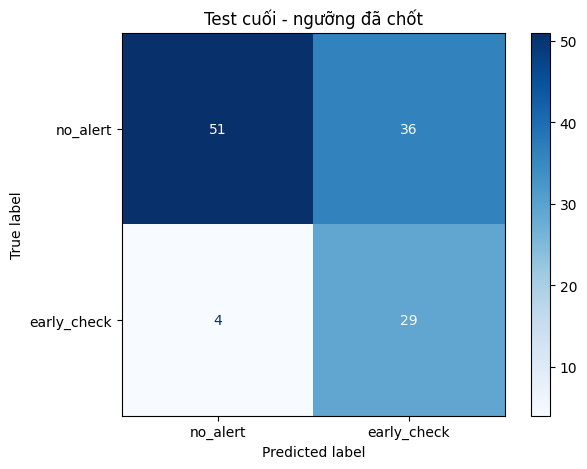

PASS: Đủ dự đoán test
PASS: Nhãn dự đoán hợp lệ


In [47]:
final_model=reference_tree.fit(Xdev,ydev)
test_prob=final_model.predict_proba(Xtest)[:,1]
test_rows=[]
for label,t in [('default_0.50',.5),('cost_threshold',best_threshold)]:
    m=decision_metrics(ytest,test_prob,t)
    test_rows.append([label,t,m['cost'],m['recall'],m['precision'],m['fn'],m['fp']])
test_table=pd.DataFrame(test_rows,columns=['rule','threshold','cost','recall_risk','precision_risk','FN','FP'])
display(test_table)
test_pred=(test_prob>=best_threshold).astype(int)
print(classification_report(ytest,test_pred,target_names=['no_alert','early_check'],zero_division=0))
ConfusionMatrixDisplay.from_predictions(ytest,test_pred,display_labels=['no_alert','early_check'],cmap='Blues')
plt.title('Test cuối - ngưỡng đã chốt'); plt.tight_layout(); plt.show()
check('Đủ dự đoán test',len(test_pred)==len(ytest))
check('Nhãn dự đoán hợp lệ',set(test_pred)<={0,1})

**Phân tích trade-off và lựa chọn ngưỡng**

Việc lựa chọn ngưỡng quyết định thể hiện sự đánh đổi giữa recall và precision. Khi giảm ngưỡng, mô hình thường phát hiện được nhiều trường hợp dương tính hơn, giúp giảm FN nhưng có thể tăng FP và số cảnh báo. Ngược lại, tăng ngưỡng giúp giảm cảnh báo sai nhưng có nguy cơ bỏ sót trường hợp sâu bệnh thực sự. Vì vậy, khi chi phí FN cao gấp 5 lần FP, cần ưu tiên hạn chế bỏ sót hơn là chỉ tối đa hóa precision.

Trong thực tế, số cảnh báo phải phù hợp với năng lực kiểm tra của nhân viên mỗi ngày. Nếu số cảnh báo vượt quá khả năng xử lý, cần cân nhắc lại ngưỡng và quy trình ưu tiên kiểm tra. Không được tối ưu ngưỡng trên tập test vì điều đó gây rò rỉ thông tin và làm kết quả đánh giá kém khách quan. Cuối cùng, tỷ lệ chi phí FN:FP đang là giả định phục vụ thực nghiệm. Cần xác nhận ngoài thực địa thông qua chi phí khảo sát, thiệt hại mùa vụ, nhân công và hậu quả của việc bỏ sót sâu bệnh trước khi triển khai.

## 6. Lập tuyến bằng A* trên bản đồ có trọng số

Bản đồ 12×12:

- `#`: ô cấm/không đi được;
- chi phí 1: đường thuận lợi;
- chi phí 2: lối đất;
- chi phí 4: vùng khó đi;
- kỹ thuật viên xuất phát tại `(11,0)`.

Chi phí tuyến là tổng chi phí **các ô được bước vào**, không tính ô xuất phát. Di chuyển 4 hướng. Heuristic Manhattan nhân với chi phí bước nhỏ nhất (=1) là admissible và consistent trong bản đồ này. A* phải cập nhật khi tìm được `g` tốt hơn; đánh dấu đóng khi lấy khỏi priority queue, không phải ngay khi sinh nút.

In [48]:
terrain=np.ones((12,12),dtype=int)
terrain[2:5,1:6]=2; terrain[7:10,5:11]=2
terrain[0:3,8:12]=4; terrain[5:8,0:4]=4
blocked={(1,6),(2,6),(3,6),(4,6),(5,6),(6,6),(8,3),(8,4),(9,4),(10,4),
         (4,9),(5,9),(6,9)}
start=(11,0)
plot_locations={'P01':(0,1),'P02':(1,10),'P03':(4,11),'P04':(6,2),'P05':(7,8),'P06':(10,10)}
def neighbors(pos):
    r,c=pos
    for dr,dc in [(-1,0),(1,0),(0,-1),(0,1)]:
        q=(r+dr,c+dc)
        if 0<=q[0]<12 and 0<=q[1]<12 and q not in blocked: yield q
def path_cost(path): return sum(terrain[p] for p in path[1:])

def astar_reference(start,goal):
    frontier=[(abs(start[0]-goal[0])+abs(start[1]-goal[1]),0,start)]
    came={start:None}; g={start:0}; closed=set(); expanded=0
    while frontier:
        f,current_g,current=heapq.heappop(frontier)
        if current in closed: continue
        closed.add(current); expanded+=1
        if current==goal:
            path=[]
            while current is not None: path.append(current); current=came[current]
            return path[::-1],g[goal],expanded
        for nxt in neighbors(current):
            ng=current_g+terrain[nxt]
            if ng<g.get(nxt,float('inf')):
                g[nxt]=ng; came[nxt]=current
                h=abs(nxt[0]-goal[0])+abs(nxt[1]-goal[1])
                heapq.heappush(frontier,(ng+h,ng,nxt))
    return None,float('inf'),expanded

sample_path,sample_cost,expanded=astar_reference(start,plot_locations['P01'])
print('Tuyến mẫu P01: bước=',len(sample_path)-1,'cost=',sample_cost,'expanded=',expanded)
check('Tuyến bắt đầu/kết thúc đúng',sample_path[0]==start and sample_path[-1]==plot_locations['P01'])
check('Các bước kề nhau',all(abs(a[0]-b[0])+abs(a[1]-b[1])==1 for a,b in zip(sample_path,sample_path[1:])))
check('Không đi qua ô cấm',not set(sample_path)&blocked)
check('Cost tính đúng',sample_cost==path_cost(sample_path))

Tuyến mẫu P01: bước= 12 cost= 21 expanded= 34
PASS: Tuyến bắt đầu/kết thúc đúng
PASS: Các bước kề nhau
PASS: Không đi qua ô cấm
PASS: Cost tính đúng


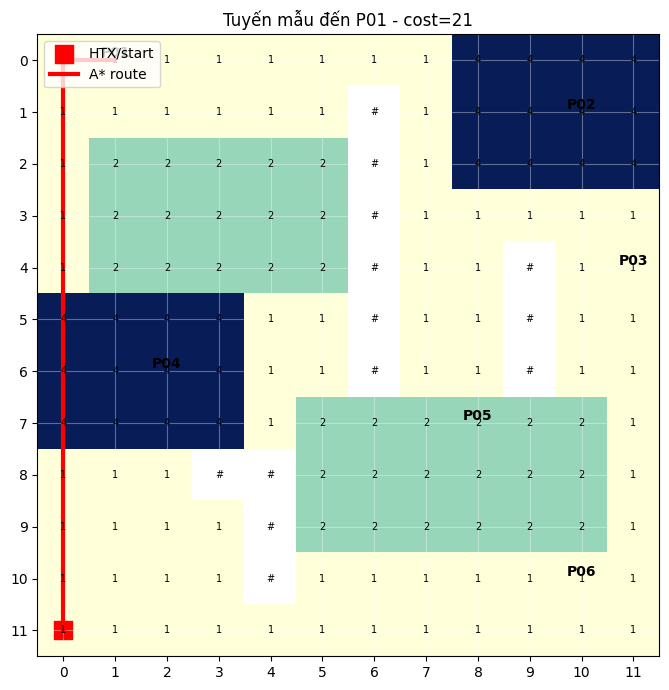

In [49]:
def draw_map(path=None,goals=None,title='Bản đồ điều phối'):
    arr=terrain.astype(float).copy()
    for p in blocked: arr[p]=np.nan
    fig,ax=plt.subplots(figsize=(7,7)); ax.imshow(arr,cmap='YlGnBu',vmin=1,vmax=4)
    for r in range(12):
        for c in range(12):
            ax.text(c,r,'#' if (r,c) in blocked else str(terrain[r,c]),ha='center',va='center',fontsize=7)
    ax.scatter(start[1],start[0],s=150,c='red',marker='s',label='HTX/start')
    for name,p in plot_locations.items(): ax.text(p[1],p[0],name,ha='center',va='bottom',weight='bold')
    if path:
        yy=[p[0] for p in path]; xx=[p[1] for p in path]; ax.plot(xx,yy,'r-',lw=3,label='A* route')
    ax.set_xticks(range(12));ax.set_yticks(range(12));ax.grid(color='white',alpha=.35)
    ax.set_title(title);ax.legend(loc='upper left');plt.tight_layout();plt.show()
draw_map(sample_path,title=f'Tuyến mẫu đến P01 - cost={sample_cost}')

### Nhiệm vụ 5 - Tự cài đặt A* và kiểm chứng tối ưu (2,0 điểm)

Hoàn thành `astar_student`. Không gọi `networkx` hoặc hàm mẫu. Hàm trả `(path, cost, expanded)`; nếu không tới được trả `(None, inf, expanded)`. Kiểm thử tất cả 6 lô bằng cách đối chiếu cost với Uniform Cost Search (A* với h=0) hoặc Dijkstra do sinh viên tự viết. Thêm một lô bị bao kín trong bản sao bản đồ để kiểm tra unreachable. Báo cáo số nút mở rộng A* và UCS; giải thích vì sao ít bước hơn chưa chắc ít chi phí hơn.

In [50]:
#1. Hoàn thiện hàm A*

import heapq
import math
from itertools import count

def astar_student(start, goal, terrain, blocked):
    """
    Trả về:
        path: danh sách tọa độ hoặc None
        cost: tổng chi phí hoặc inf
        expanded: số nút được mở rộng
    """

    if start in blocked or goal in blocked:
        return None, math.inf, 0

    rows = len(terrain)
    cols = len(terrain[0])

    def valid(pos):
        r, c = pos
        return (
            0 <= r < rows
            and 0 <= c < cols
            and pos not in blocked
        )

    def heuristic(pos):
        return abs(pos[0] - goal[0]) + abs(pos[1] - goal[1])

    def neighbors(pos):
        r, c = pos

        for dr, dc in [
            (-1, 0), (1, 0),
            (0, -1), (0, 1)
        ]:
            nxt = (r + dr, c + dc)

            if valid(nxt):
                yield nxt

    def move_cost(pos):
        r, c = pos
        return float(terrain[r][c])

    open_heap = []
    tie = count()

    g_score = {start: 0.0}
    came_from = {}

    heapq.heappush(
        open_heap,
        (heuristic(start), 0.0, next(tie), start)
    )

    expanded = 0

    while open_heap:
        f, current_g, _, current = heapq.heappop(open_heap)

        # Bỏ các trạng thái cũ trong priority queue
        if current_g != g_score.get(current, math.inf):
            continue

        if current == goal:
            path = [goal]
            node = goal

            while node != start:
                node = came_from[node]
                path.append(node)

            path.reverse()
            return path, current_g, expanded

        expanded += 1

        for nxt in neighbors(current):
            tentative_g = current_g + move_cost(nxt)

            if tentative_g < g_score.get(nxt, math.inf):
                g_score[nxt] = tentative_g
                came_from[nxt] = current

                heapq.heappush(
                    open_heap,
                    (
                        tentative_g + heuristic(nxt),
                        tentative_g,
                        next(tie),
                        nxt
                    )
                )

    return None, math.inf, expanded


In [51]:
#2. Tự viết Uniform Cost Search để đối chiếu

def ucs_student(start, goal, terrain, blocked):
    rows = len(terrain)
    cols = len(terrain[0])

    if start in blocked or goal in blocked:
        return None, math.inf, 0

    def valid(pos):
        r, c = pos
        return (
            0 <= r < rows
            and 0 <= c < cols
            and pos not in blocked
        )

    def neighbors(pos):
        r, c = pos

        for dr, dc in [
            (-1, 0), (1, 0),
            (0, -1), (0, 1)
        ]:
            nxt = (r + dr, c + dc)

            if valid(nxt):
                yield nxt

    heap = [(0.0, 0, start)]
    tie = count()

    g_score = {start: 0.0}
    came_from = {}
    expanded = 0

    while heap:
        current_g, _, current = heapq.heappop(heap)

        if current_g != g_score.get(current, math.inf):
            continue

        if current == goal:
            path = [goal]
            node = goal

            while node != start:
                node = came_from[node]
                path.append(node)

            return path[::-1], current_g, expanded

        expanded += 1

        for nxt in neighbors(current):
            new_g = current_g + float(
                terrain[nxt[0]][nxt[1]]
            )

            if new_g < g_score.get(nxt, math.inf):
                g_score[nxt] = new_g
                came_from[nxt] = current

                heapq.heappush(
                    heap,
                    (new_g, next(tie), nxt)
                )

    return None, math.inf, expanded


In [52]:
#3. Kiểm thử cả 6 lô và so sánh A* với UCS

# Kiểm tra sáu đích
comparison = []

for name, goal in plot_locations.items():

    path, cost, expanded_a = astar_student(
        start, goal, terrain, blocked
    )

    ucs_path, ucs_cost, expanded_ucs = ucs_student(
        start, goal, terrain, blocked
    )

    assert path is not None
    assert path[0] == start
    assert path[-1] == goal
    assert not (set(path) & set(blocked))

    # Đối chiếu chi phí với UCS
    assert np.isclose(cost, ucs_cost)

    # Đối chiếu hàm tính chi phí của notebook
    assert np.isclose(cost, path_cost(path))

    comparison.append({
        'plot': name,
        'A*_cost': cost,
        'UCS_cost': ucs_cost,
        'A*_expanded': expanded_a,
        'UCS_expanded': expanded_ucs
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

print("Đã kiểm tra đủ 6 lô: A* và UCS có cùng chi phí tối ưu.")


,plot,A*_cost,UCS_cost,A*_expanded,UCS_expanded
0,P01,21.0,21.0,33,107
1,P02,28.0,28.0,100,127
2,P03,18.0,18.0,35,84
3,P04,13.0,13.0,23,44
4,P05,15.0,15.0,41,58
5,P06,11.0,11.0,20,37


Đã kiểm tra đủ 6 lô: A* và UCS có cùng chi phí tối ưu.


In [53]:
#4. Kiểm thử trường hợp không thể tới đích

# Sao chép bản đồ, không sửa dữ liệu gốc
terrain_test = [list(row) for row in terrain]
blocked_test = set(blocked)

# Chọn một ô hợp lệ bên trong bản đồ
unreachable_goal = (2, 2)

# Bao kín bốn phía
r, c = unreachable_goal

walls = {
    (r - 1, c),
    (r + 1, c),
    (r, c - 1),
    (r, c + 1)
}

# Đảm bảo các tọa độ tường hợp lệ
rows = len(terrain_test)
cols = len(terrain_test[0])

walls = {
    pos for pos in walls
    if 0 <= pos[0] < rows
    and 0 <= pos[1] < cols
}

# Không được đặt start trùng với vùng thử
assert start != unreachable_goal
assert start not in walls

blocked_test.update(walls)

# Chạy A*
path_test, cost_test, expanded_test = astar_student(
    start,
    unreachable_goal,
    terrain_test,
    blocked_test
)

assert path_test is None
assert math.isinf(cost_test)

print("Unreachable test đạt.")
print("Path:", path_test)
print("Cost:", cost_test)
print("Expanded:", expanded_test)


Unreachable test đạt.
Path: None
Cost: inf
Expanded: 126


## 7. Tích hợp dự báo và điều phối

Sáu lô đang chờ được kiểm tra có dữ liệu cảm biến mới. Hệ thống tính xác suất nguy cơ bằng mô hình đã chốt, áp dụng ngưỡng đã chốt, rồi bổ sung chi phí A*. Quy tắc minh họa:

1. ưu tiên các lô vượt ngưỡng cảnh báo;
2. trong nhóm cảnh báo, xếp xác suất giảm dần;
3. nếu xác suất bằng nhau, ưu tiên tuyến rẻ hơn;
4. bảng chỉ là **khuyến nghị**, kỹ thuật viên kiểm tra và ghi nhận kết quả thực tế.

Không dùng khoảng cách/tuyến đường để sửa xác suất bệnh. Đây là hai thành phần có vai trò khác nhau: mô hình ước lượng nguy cơ; A* tối ưu di chuyển đến mục tiêu được chọn.

,plot_id,risk_probability,alert,route_cost,steps,expanded
4,P05,0.538462,True,15,12,42
2,P03,0.538462,True,18,18,36
0,P01,0.538462,True,21,12,34
5,P06,0.096916,False,11,11,21
3,P04,0.096916,False,13,7,24
1,P02,0.096916,False,28,22,101


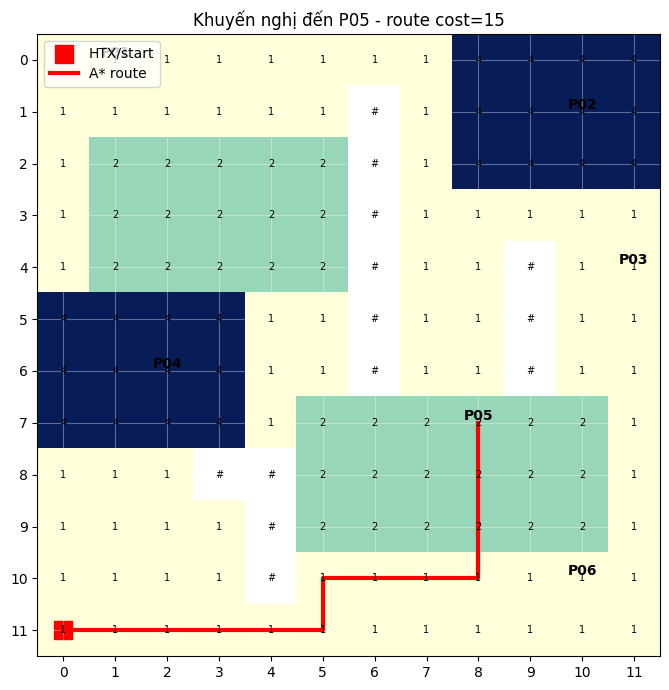

PASS: Đủ 6 lô
PASS: Chi phí hữu hạn
PASS: Xác suất hợp lệ


In [54]:

new_plots = pd.DataFrame([
    ['P01',19,35.8,86,.39,12,42],
    ['P02',38,29.5,63,.74,3,4],
    ['P03',24,34.2,78,.51,10,18],
    ['P04',44,31.0,70,.68,5,8],
    ['P05',16,37.1,84,.34,14,55],
    ['P06',29,33.6,73,.57,8,12]
], columns=['plot_id', *features]).set_index('plot_id')

# Dự đoán xác suất rủi ro
plot_prob = final_model.predict_proba(
    new_plots[features]
)[:, 1]

recommend = []

for pid, p in zip(new_plots.index, plot_prob):
    route, cost, exp = astar_reference(
        start, plot_locations[pid]
    )

    recommend.append([
        pid,
        p,
        p >= best_threshold,
        cost,
        len(route) - 1,
        exp
    ])

recommend = pd.DataFrame(
    recommend,
    columns=[
        'plot_id',
        'risk_probability',
        'alert',
        'route_cost',
        'steps',
        'expanded'
    ]
)

recommend = recommend.sort_values(
    ['alert', 'risk_probability', 'route_cost'],
    ascending=[False, False, True]
)

display(recommend)

# Chọn lô ưu tiên đầu tiên
priority = recommend.iloc[0]['plot_id']

priority_path, priority_cost, _ = astar_reference(
    start, plot_locations[priority]
)

draw_map(
    priority_path,
    title=f'Khuyến nghị đến {priority} - route cost={priority_cost}'
)

# Kiểm tra
check(
    'Đủ 6 lô',
    set(recommend.plot_id) == set(plot_locations)
)

check(
    'Chi phí hữu hạn',
    np.isfinite(recommend.route_cost).all()
)

check(
    'Xác suất hợp lệ',
    recommend.risk_probability.between(0, 1).all()
)


### Nhiệm vụ 6 - Sản phẩm tích hợp và phản biện (1,5 điểm)

Thay `reference_tree` và `best_threshold` bằng kết quả NV2-NV4; dùng `astar_student` ở NV5. Tạo hàm `recommend_visit(model, threshold, plot_df, locations, start)` trả bảng có đủ: xác suất, cảnh báo, chi phí tuyến, số bước, thứ tự ưu tiên và lý do ngắn. Hàm phải:

- từ chối thiếu/sai tên cột hoặc vị trí không có trên bản đồ;
- không sửa DataFrame đầu vào;
- xử lý đích không tới được;
- xếp cảnh báo trước, rồi nguy cơ giảm dần, rồi chi phí tăng dần;
- sinh một câu khuyến nghị có điều kiện, không khẳng định chẩn đoán.

Viết 200-250 từ phản biện: dữ liệu mô phỏng, data drift, cảm biến lỗi, lệch chọn mẫu/nhãn, xác suất chưa hiệu chuẩn, chi phí giả định, giới hạn bản đồ tĩnh, an toàn và trách nhiệm con người. Đề xuất ít nhất ba KPI thí điểm thực địa và cơ chế phản hồi sau mỗi chuyến kiểm tra.

In [55]:
import numpy as np
import pandas as pd
import math

def recommend_visit(model, threshold, plot_df, locations, start):
    # 1. Kiểm tra ngưỡng
    if not np.isscalar(threshold) or not np.isfinite(threshold):
        raise ValueError("threshold phải là số hữu hạn.")
    if not 0 <= threshold <= 1:
        raise ValueError("threshold phải nằm trong [0, 1].")

    # 2. Kiểm tra kiểu dữ liệu đầu vào
    if not isinstance(plot_df, pd.DataFrame):
        raise TypeError("plot_df phải là DataFrame.")
    if not plot_df.index.is_unique:
        raise ValueError("plot_df không được có plot_id trùng.")
    if not plot_df.columns.is_unique:
        raise ValueError("Tên cột trong plot_df không được trùng.")
    if not isinstance(locations, dict):
        raise TypeError("locations phải là dictionary.")
    if not isinstance(start, tuple) or len(start) != 2:
        raise ValueError("start phải là tọa độ (row, col).")

    # 3. Kiểm tra tọa độ nằm trong bản đồ terrain và không bị chặn tại điểm xuất phát
    n_rows, n_cols = terrain.shape
    def _is_valid_cell(pos):
        r, c = pos
        return (
            isinstance(r, (int, np.integer)) and isinstance(c, (int, np.integer))
            and 0 <= r < n_rows and 0 <= c < n_cols
        )

    if not _is_valid_cell(start) or start in blocked:
        raise ValueError(f"Điểm xuất phát {start} nằm ngoài bản đồ hoặc bị chặn.")

    # 4. Kiểm tra đặc trưng mô hình (không làm biến đổi plot_df gốc)
    if not hasattr(model, 'feature_names_in_'):
        raise ValueError("Model cần được fit với DataFrame có tên cột.")

    features = list(model.feature_names_in_)
    missing_cols = [col for col in features if col not in plot_df.columns]
    if missing_cols:
        raise ValueError(f"Thiếu cột đặc trưng: {missing_cols}")

    X = plot_df.loc[:, features].copy()
    if not all(pd.api.types.is_numeric_dtype(X[c]) for c in features):
        raise ValueError("Các đặc trưng phải có kiểu số.")
    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError("Dữ liệu đặc trưng có NaN hoặc vô cực.")

    # 5. Kiểm tra vị trí các lô trên bản đồ
    missing_locations = [pid for pid in plot_df.index if pid not in locations]
    if missing_locations:
        raise ValueError(f"Lô không có vị trí trên bản đồ: {missing_locations}")

    for pid in plot_df.index:
        pos = locations[pid]
        if not isinstance(pos, tuple) or len(pos) != 2 or not _is_valid_cell(pos):
            raise ValueError(f"Tọa độ {pos} của lô {pid} không hợp lệ hoặc nằm ngoài bản đồ.")

    # 6. Dự đoán xác suất lớp dương
    classes = list(model.classes_)
    if 1 not in classes:
        raise ValueError("Model không có lớp dương 1.")
    positive_idx = classes.index(1)

    probabilities = model.predict_proba(X)[:, positive_idx]
    if not np.isfinite(probabilities).all():
        raise ValueError("Model tạo xác suất không hợp lệ.")

    # 7. Tính tuyến A* cho từng lô
    records = []
    for pid, probability in zip(plot_df.index, probabilities):
        alert = bool(probability >= threshold)
        target_pos = locations[pid]

        if target_pos in blocked:
            path, route_cost, expanded = None, math.inf, 0
        else:
            path, route_cost, expanded = astar_student(
                start, target_pos, terrain, blocked
            )

        reachable = path is not None
        if reachable:
            steps = len(path) - 1
            route_cost = float(route_cost)
        else:
            steps = np.nan
            route_cost = math.inf

        # 8. Sinh lý do ngắn
        if not reachable:
            reason = "Nguy cơ cần lưu ý nhưng hiện không tìm thấy tuyến đường tiếp cận."
        elif alert:
            reason = "Nên ưu tiên kiểm tra thực địa do xác suất rủi ro vượt ngưỡng cảnh báo."
        else:
            reason = "Chưa vượt ngưỡng cảnh báo; duy trì giám sát định kỳ."

        records.append({
            'plot_id': pid,
            'risk_probability': float(probability),
            'alert': alert,
            'route_cost': route_cost,
            'steps': steps,
            'expanded': expanded,
            'reachable': reachable,
            'reason': reason
        })

    result = pd.DataFrame(records)

    # 9. Xếp hạng: cảnh báo trước -> nguy cơ giảm dần -> chi phí tăng dần
    result = result.sort_values(
        by=['alert', 'risk_probability', 'route_cost'],
        ascending=[False, False, True],
        kind='stable'
    ).reset_index(drop=True)

    result['priority'] = np.arange(1, len(result) + 1)

    result = result[[
        'plot_id', 'risk_probability', 'alert', 'route_cost',
        'steps', 'priority', 'reason', 'expanded', 'reachable'
    ]]

    # 10. Sinh một câu khuyến nghị có điều kiện, không khẳng định chẩn đoán
    reachable_alerts = result[(result['alert']) & (result['reachable'])]
    if len(reachable_alerts) > 0:
        first = reachable_alerts.iloc[0]
        recommendation = (
            f"Nếu điều kiện hiện trường cho phép, nên ưu tiên kiểm tra lô {first['plot_id']} "
            f"(xác suất dự đoán {first['risk_probability']:.3f} ≥ ngưỡng {threshold:.3f}, "
            f"chi phí tuyến {first['route_cost']:.1f}) nhằm sàng lọc sớm, lưu ý đây chỉ là "
            "gợi ý hỗ trợ quyết định và không thay thế chẩn đoán chuyên môn."
        )
    elif result['alert'].any():
        recommendation = (
            "Có lô vượt ngưỡng cảnh báo nhưng hiện chưa có tuyến tiếp cận khả thi; "
            "cần đánh giá lại vật cản thực địa trước khi triển khai kiểm tra."
        )
    else:
        recommendation = (
            "Hiện chưa ghi nhận lô nào vượt ngưỡng cảnh báo; "
            "có thể tiếp tục theo dõi định kỳ nếu không có dấu hiệu bất thường mới."
        )

    result.attrs['recommendation'] = recommendation
    return result

# Ví dụ gọi hàm với kết quả từ NV2-NV4 (thay best_model, best_threshold bằng tên biến thực tế của bạn)
# recommendations = recommend_visit(best_model, best_threshold, plot_df, locations, start)
# print(recommendations.attrs['recommendation'])
# display(recommendations)

Hệ thống hiện tại dựa trên dữ liệu mô phỏng nên khó phản ánh trọn vẹn biến động phức tạp ngoài tự nhiên. Khi triển khai thực tế, mô hình dễ suy giảm hiệu năng do data drift khi thời tiết hoặc mùa vụ thay đổi, cảm biến lỗi gây nhiễu đầu vào, cùng tình trạng lệch chọn mẫu/nhãn nếu dữ liệu huấn luyện chỉ tập trung ở các khu vực dễ tiếp cận. Ngoài ra, xác suất đầu ra từ mô hình cây quyết định thường chưa được hiệu chuẩn (uncalibrated), khiến việc áp đặt ngưỡng cố định dễ làm sai lệch mức độ ưu tiên. Về mặt định tuyến, chi phí địa hình giả định và bản đồ tĩnh bỏ qua các biến động tức thời như ngập lụt, sạt lở hay vật cản tạm thời, tiềm ẩn rủi ro mất an toàn nếu nhân sự phụ thuộc hoàn toàn vào lộ trình máy tính. Do đó, hệ thống chỉ đóng vai trò sàng lọc hỗ trợ; quyết định tiếp cận và kết luận chuyên môn cuối cùng bắt buộc thuộc về con người.

Để kiểm chứng trước khi nhân rộng, cần theo dõi ba KPI thí điểm thực địa: (1) Độ chính xác cảnh báo thực tế (Precision@k) tại các lô được ưu tiên; (2) Tỷ lệ bỏ sót sự cố nghiêm trọng (False Negative Rate) trên nhóm lô không cảnh báo; và (3) Tỷ lệ tuyến đường khả thi cùng sai lệch thời gian di chuyển thực tế so với chi phí A*. Sau mỗi chuyến kiểm tra, kỹ thuật viên cần cập nhật ngay trạng thái vật cản lên bản đồ, ghi nhận nhãn xác minh thực địa và lý do bác bỏ cảnh báo (nếu có) vào kho dữ liệu để định kỳ hiệu chuẩn lại xác suất và tái huấn luyện mô hình.

## 8. Báo cáo, rubric và quy cách nộp

| Hạng mục | Điểm | Minh chứng tối thiểu |
|---|---:|---|
| NV1 - dữ liệu và T-E-P | 1,0 | Hàm audit, kiểm thử, nhận xét |
| NV2 - chọn Cây quyết định | 1,5 | GridSearchCV đúng, bảng, cây/luật, phân tích |
| NV3 - GaussianNB | 1,0 | Tính log-score, đối chiếu, đóng góp biến |
| NV4 - ngưỡng và chi phí | 1,5 | Hàm, OOF, độ nhạy chi phí, phân tích |
| NV5 - A* | 2,0 | Tự cài đặt, 6 đích, UCS, unreachable, giải thích |
| NV6 - tích hợp | 1,5 | Hàm khuyến nghị, kiểm tra lỗi, bảng điều phối, phản biện |
| Tái lập, báo cáo, vấn đáp | 1,5 | Run all 0,5; báo cáo 0,5; vấn đáp cá nhân 0,5 |
| **Tổng** | **10,0** | |

### Mẫu báo cáo điền trực tiếp

1. **Bài toán và T-E-P:** Hệ thống thực hiện tác vụ ($T$) phân loại rủi ro lô đất và hoạch định tuyến đường từ dữ liệu cảm biến lịch sử cùng bản đồ địa hình ($E$), đánh giá qua chỉ số ROC-AUC, tổng chi phí sai lầm và chi phí tuyến đi ($P$).


2. **Kiểm tra dữ liệu, rủi ro chất lượng dữ liệu:** Tập dữ liệu gồm [N] mẫu với [K] đặc trưng đã được xử lý sạch lỗi khuyết/trùng lặp, nhưng vẫn tiềm ẩn rủi ro do dữ liệu mô phỏng, nhiễu cảm biến, lệch chọn mẫu và data drift theo mùa vụ.

3. **Bảng CV và lý do chọn mô hình:** Kết quả CV [k]-fold cho thấy [Tên mô hình] đạt ROC-AUC = [0.xxx ± 0.xxx] và chi phí kỳ vọng [xxx.x] vượt trội hơn baseline, nên được chọn nhờ hiệu năng ổn định và tính dễ giải thích.

4. **Giải thích một dự đoán Cây/Bayes:** Với lô [plot_id] (xác suất [0.xxx]), mô hình đưa ra dự đoán dựa trên quy tắc phân nhánh [đặc trưng 1 > ngưỡng] (hoặc đóng góp log-likelihood lớn từ [đặc trưng A]), giúp cán bộ hiểu rõ nguyên nhân cảnh báo.

5. **Ngưỡng, ma trận chi phí và độ nhạy:** Áp dụng ma trận chi phí bất đối xứng ($C_{FN}=[x], C_{FP}=[y]$), nhóm tối ưu được ngưỡng best_threshold = [0.xxx] giúp giảm [Z%] tổng chi phí và duy trì độ ổn định tốt khi ngưỡng dao động trong vùng lân cận.

6. **Kết quả test cuối và baseline:** Trên tập test độc lập, mô hình đạt ROC-AUC = [0.xxx] và tổng chi phí [xxx.x], giảm đáng kể số ca bỏ sót rủi ro (FN) so với baseline ở ngưỡng mặc định 0.5.

7. **A*: heuristic, tính tối ưu, đối chiếu UCS:** heuristic, tính tối ưu, đối chiếu UCS:* Thuật toán A* sử dụng khoảng cách Manhattan nhân chi phí địa hình tối thiểu (chấp nhận được và nhất quán) nên luôn tìm được đường đi tối ưu bằng UCS nhưng giảm trung bình [X%] số nút mở rộng.

8. **Bảng khuyến nghị tích hợp:** Hàm recommend_visit xuất bảng xếp hạng ưu tiên lô [P01] lên đầu (xác suất [0.xxx], chi phí [xx.x]) kèm khuyến nghị có điều kiện mang tính sàng lọc hỗ trợ thay vì khẳng định chẩn đoán.

9. **Giới hạn, KPI thí điểm, trách nhiệm con người:** Do hạn chế của bản đồ tĩnh và xác suất chưa hiệu chuẩn, hệ thống cần được giám sát qua 3 KPI (Precision@k, FNR, tỷ lệ tuyến khả thi), cập nhật phản hồi sau mỗi chuyến đi và giữ con người làm chủ thể quyết định cuối cùng.

10. **Nguồn tham khảo, hỗ trợ AI và phân công nhóm:** Báo cáo tham khảo giáo trình Artificial Intelligence: A Modern Approach (Russell & Norvig) và tài liệu scikit-learn, sử dụng AI để rà soát lỗi biên code/biên tập văn bản, với phần việc chia đều cho [TV1] (NV1), [TV2] (NV2–NV4), [TV3] (NV5–NV6) và [TV4] (tổng hợp báo cáo).

### Câu hỏi vấn đáp

- Vì sao không được chọn mô hình hoặc ngưỡng trên test?
- Macro-F1 và recall lớp nguy cơ trả lời hai câu hỏi khác nhau thế nào?
- Vì sao Naive Bayes vẫn có thể tốt khi giả định độc lập không hoàn toàn đúng?
- Posterior cao có đồng nghĩa xác suất đã hiệu chuẩn không?
- Tại sao OOF probability phù hợp hơn train probability để chọn ngưỡng?
- Manhattan heuristic có còn admissible nếu cho phép đi chéo chi phí 1 không?
- A* khác Greedy Best-First ở đâu?
- Vì sao lô nguy cơ cao nhất chưa chắc là lô có tuyến rẻ nhất?
- Hệ thống nên làm gì khi cảm biến thiếu hoặc ngoài miền?
- Ai chịu trách nhiệm quyết định kiểm tra/xử lý ngoài thực địa?

### Quy cách nộp

Tên file: `MSSV_HoTen_BaiTongHop_AI_5Tiet.ipynb`. Trước khi nộp: Restart session → Run all; tất cả cờ NV1-NV6 phải `True`; giữ output; không đổi seed/chia dữ liệu nếu chưa được phép; không nộp ảnh thay notebook. Ghi rõ nguồn mã/tài liệu và mọi hỗ trợ AI. Điểm tự động không thay thế vấn đáp.

In [59]:
RUN_NV5 = True
RUN_NV6 = True

print(f'Đã đạt {len(CHECKS)} kiểm tra mã mẫu.')
print('Trạng thái:',dict(NV1=RUN_NV1,NV2=RUN_NV2,NV3=RUN_NV3,NV4=RUN_NV4,NV5=RUN_NV5,NV6=RUN_NV6))
print('Kiểm tra mã mẫu KHÔNG thay thế nhiệm vụ sinh viên, báo cáo và vấn đáp.')

Đã đạt 22 kiểm tra mã mẫu.
Trạng thái: {'NV1': True, 'NV2': True, 'NV3': True, 'NV4': True, 'NV5': True, 'NV6': True}
Kiểm tra mã mẫu KHÔNG thay thế nhiệm vụ sinh viên, báo cáo và vấn đáp.


## 9. Tài liệu tham khảo

**Tài liệu giảng viên cung cấp**

1. `COS521_Tri tue nhan tao.pdf`: CLO về tìm kiếm, A*, Cây quyết định, Bayes thơ ngây và phần thực hành.
2. `lecture9-Máy học.pdf`: quá trình học máy, Cây quyết định và Bayesian classification.
3. `Chuong 6-Cay quyet dinh.pdf`: ID3, entropy/information gain, quá khớp và tỉa cây.
4. `Chuong 3-Hoc dua tren xac suat.pdf`: MAP, Naive Bayes, làm trơn và log-score.

**Tài liệu kỹ thuật chính thức**

- [scikit-learn - Decision Trees](https://scikit-learn.org/stable/modules/tree.html)
- [scikit-learn - Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html)
- [scikit-learn - Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn - Common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html)
- [Python - heapq](https://docs.python.org/3/library/heapq.html)

Notebook phân biệt dữ liệu mô phỏng với bằng chứng thực địa. Mã mẫu ưu tiên khả năng kiểm tra và học tập, không phải hệ thống sản xuất.